In [2]:
!pip install pandas numpy matplotlib seaborn

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
data = {
    'SessionID': range(1, 16),

    'UserID': [101, 102, 103, 104, 105, 106, 107, 108,
               109, 110, 111, 112, 113, 114, 115],

    'Page': [
        'Home', 'Products', 'Home', 'Contact', 'Home',
        'Products', 'Pricing', 'Home', 'Products', 'Home',
        'Pricing', 'Contact', 'Home', 'Products', 'Home'
    ],

    'PageViews': [5, 3, 2, 1, 6, 4, 2, 3, 5, 1, 4, 2, 6, 3, 2],

    'SessionDuration': [300, 180, 60, 20, 420, 240, 90, 150,
                        360, 15, 210, 45, 480, 120, 75],

    'TrafficSource': [
        'Google', 'Social Media', 'Direct', 'Google', 'Direct',
        'Social Media', 'Google', 'Direct', 'Google', 'Social Media',
        'Direct', 'Google', 'Google', 'Social Media', 'Direct'
    ],

    'Device': [
        'Mobile', 'Desktop', 'Mobile', 'Mobile', 'Desktop',
        'Mobile', 'Desktop', 'Mobile', 'Desktop', 'Mobile',
        'Desktop', 'Mobile', 'Desktop', 'Mobile', 'Mobile'
    ],

    'ExitPage': [
        'Checkout', 'Products', 'Home', 'Contact', 'Checkout',
        'Pricing', 'Pricing', 'Products', 'Checkout', 'Home',
        'Checkout', 'Contact', 'Checkout', 'Products', 'Home'
    ],

    'Converted': [
        'Yes', 'No', 'No', 'No', 'Yes',
        'No', 'No', 'No', 'Yes', 'No',
        'Yes', 'No', 'Yes', 'No', 'No'
    ]
}

df = pd.DataFrame(data)

df

,SessionID,UserID,Page,PageViews,SessionDuration,TrafficSource,Device,ExitPage,Converted
0,1,101,Home,5,300,Google,Mobile,Checkout,Yes
1,2,102,Products,3,180,Social Media,Desktop,Products,No
2,3,103,Home,2,60,Direct,Mobile,Home,No
3,4,104,Contact,1,20,Google,Mobile,Contact,No
4,5,105,Home,6,420,Direct,Desktop,Checkout,Yes
5,6,106,Products,4,240,Social Media,Mobile,Pricing,No
6,7,107,Pricing,2,90,Google,Desktop,Pricing,No
7,8,108,Home,3,150,Direct,Mobile,Products,No
8,9,109,Products,5,360,Google,Desktop,Checkout,Yes
9,10,110,Home,1,15,Social Media,Mobile,Home,No


In [5]:
print("Dataset Information:")
df.info()

print("\nDataset Statistics:")
display(df.describe())

print("\nTraffic Sources:")
print(df['TrafficSource'].value_counts())

print("\nDevice Distribution:")
print(df['Device'].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   SessionID        15 non-null     int64 
 1   UserID           15 non-null     int64 
 2   Page             15 non-null     object
 3   PageViews        15 non-null     int64 
 4   SessionDuration  15 non-null     int64 
 5   TrafficSource    15 non-null     object
 6   Device           15 non-null     object
 7   ExitPage         15 non-null     object
 8   Converted        15 non-null     object
dtypes: int64(4), object(5)
memory usage: 1.2+ KB

Dataset Statistics:


,SessionID,UserID,PageViews,SessionDuration
count,15.000000,15.000000,15.000000,15.000000
mean,8.000000,108.000000,3.266667,184.333333
std,4.472136,4.472136,1.667619,148.250110
min,1.000000,101.000000,1.000000,15.000000
25%,4.500000,104.500000,2.000000,67.500000
50%,8.000000,108.000000,3.000000,150.000000
75%,11.500000,111.500000,4.500000,270.000000
max,15.000000,115.000000,6.000000,480.000000



Traffic Sources:
TrafficSource
Google          6
Direct          5
Social Media    4
Name: count, dtype: int64

Device Distribution:
Device
Mobile     9
Desktop    6
Name: count, dtype: int64


In [6]:
total_sessions = df['SessionID'].nunique()

total_pageviews = df['PageViews'].sum()

average_duration = df['SessionDuration'].mean()

total_users = df['UserID'].nunique()

print("Total Sessions:", total_sessions)
print("Total Users:", total_users)
print("Total Page Views:", total_pageviews)
print("Average Session Duration:", round(average_duration, 2), "seconds")

Total Sessions: 15
Total Users: 15
Total Page Views: 49
Average Session Duration: 184.33 seconds


TrafficSource
Google          6
Direct          5
Social Media    4
Name: count, dtype: int64


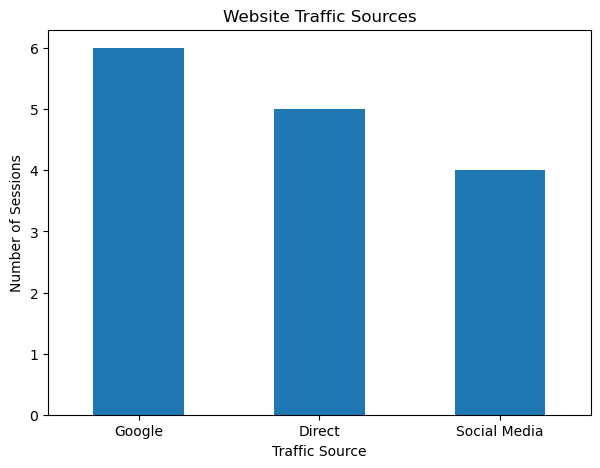

In [7]:
traffic = df['TrafficSource'].value_counts()

print(traffic)

traffic.plot(kind='bar', figsize=(7, 5))

plt.title("Website Traffic Sources")
plt.xlabel("Traffic Source")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)

plt.show()

Device
Mobile     9
Desktop    6
Name: count, dtype: int64


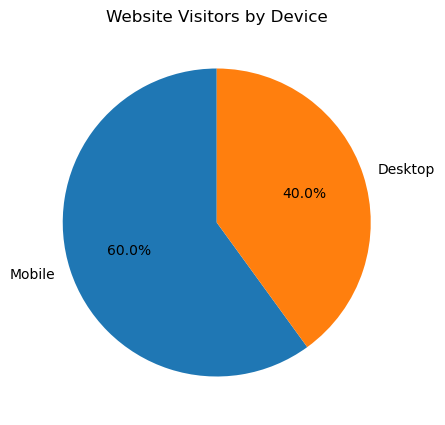

In [8]:
device_count = df['Device'].value_counts()

print(device_count)

plt.figure(figsize=(6, 5))

plt.pie(
    device_count,
    labels=device_count.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Website Visitors by Device")

plt.show()

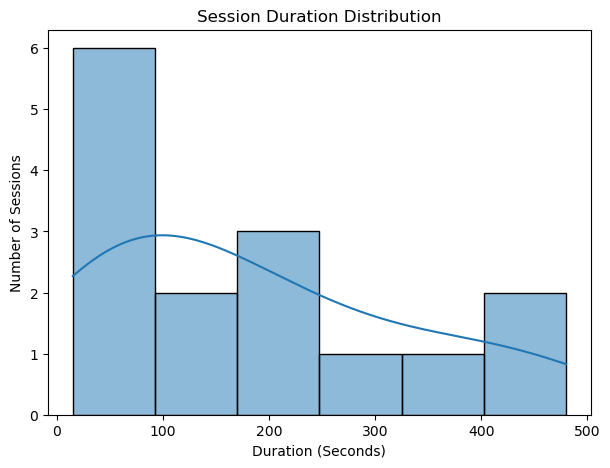

In [9]:
plt.figure(figsize=(7, 5))

sns.histplot(df['SessionDuration'], bins=6, kde=True)

plt.title("Session Duration Distribution")
plt.xlabel("Duration (Seconds)")
plt.ylabel("Number of Sessions")

plt.show()

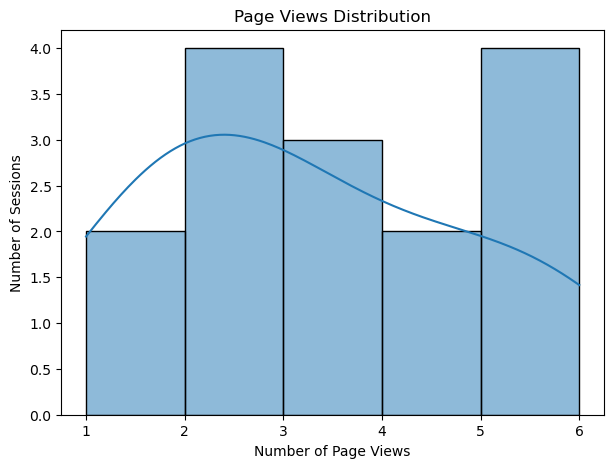

In [10]:
plt.figure(figsize=(7, 5))

sns.histplot(df['PageViews'], bins=5, kde=True)

plt.title("Page Views Distribution")
plt.xlabel("Number of Page Views")
plt.ylabel("Number of Sessions")

plt.show()

Website Exit Pages:
ExitPage
Checkout    5
Products    3
Home        3
Contact     2
Pricing     2
Name: count, dtype: int64


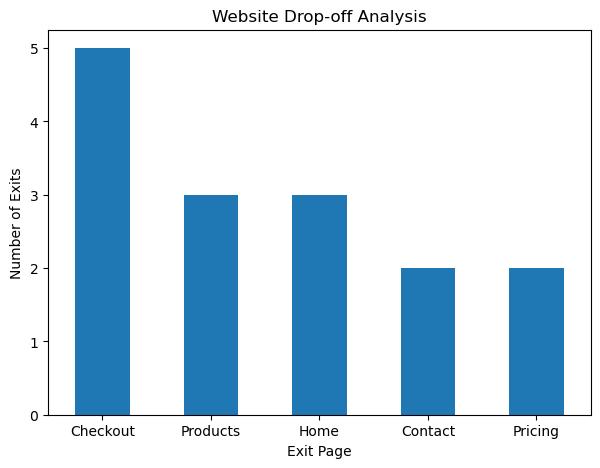

In [11]:
exit_pages = df['ExitPage'].value_counts()

print("Website Exit Pages:")
print(exit_pages)

exit_pages.plot(kind='bar', figsize=(7, 5))

plt.title("Website Drop-off Analysis")
plt.xlabel("Exit Page")
plt.ylabel("Number of Exits")
plt.xticks(rotation=0)

plt.show()